,# Análisis exploratorio (EDA) del dataset TUSZ v2.0.6

Segundo paso de la **Fase 1 (exploración de datos)**. Analiza el inventario construido en `01_inventario_tusz.ipynb` para responder a las preguntas que condicionan el resto del TFM:

- **Fase 2 (preprocesado)**: ¿qué montajes y frecuencias de muestreo hay que homogeneizar?
- **Fase 3 (predicción)**: ¿cuántas crisis tienen suficiente lead-in para recortar una ventana preictal? ¿Qué umbral usamos?
- **Fase 4 (clasificación)**: ¿cuántas crisis y pacientes hay de cada tipo?

No lee el dataset: trabaja con `edfs.csv` y `crisis.csv`, así que se ejecuta en segundos. **Requisito**: haber ejecutado antes `01_inventario_tusz.ipynb`.

## Conceptos y convención visual

- **Lead-in**: tiempo sin crisis que hay antes de cada crisis, dentro de su mismo fichero. La definición completa, con ejemplo, está al inicio de `01_inventario_tusz.ipynb`.
- **Ventana preictal**: trozo de señal antes de la crisis que el modelo aprenderá a reconocer. La elegimos nosotros y tiene que caber dentro del lead-in.

**Iconos** (los mismos en todo el TFM, definidos en `tfm_comun/iconos.py`):

| Etiquetas | | Particiones | |
|---|---|---|---|
| ⬜ `bckg` fondo | 🟩 `absz` ausencia | 🔵 `train` | entrenamiento |
| ⬛ `seiz` / `sin_tipo` crisis sin tipo | 🟪 `tcsz` tónico-clónica | 🟡 `dev` | validación |
| 🟥 `fnsz` focal no específica | 🟨 `tnsz` tónica | 🟢 `eval` | test final |
| 🟦 `gnsz` generalizada no específica | 🟫 `spsz` parcial simple | ⚪ todas | dataset completo |
| 🟧 `cpsz` parcial compleja | 🔳 `mysz` mioclónica | 🔴 | avisos |

En las figuras se usan colores a juego: azul 🔵, amarillo 🟡 y verde 🟢.

## 1. Importación de librerías

Análisis con `pandas` y figuras con `matplotlib`. Las utilidades comunes se importan del paquete `tfm_comun/`: particiones, iconos, colores y ejes de las figuras, cada uno en su módulo.

In [1]:
import sys
from pathlib import Path

# tfm_comun está en ALMA, por encima de la carpeta de la fase: lo añadimos al path de Python
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))

from collections import Counter
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from tfm_comun.rutas import RUTA_OUTPUTS_FASE_01
from tfm_comun.particiones import SPLITS
from tfm_comun.iconos import ICONO_ETIQUETA, ICONO_SPLIT, con_icono, tabla_con_iconos
from tfm_comun.colores import COLORES_SPLIT
from tfm_comun.ejes import eje_log_legible

## 2. Configuración y carga del inventario

- `RUTA_INVENTARIO`: salidas de `01_inventario_tusz.ipynb`.
- `RUTA_RESULTADOS`: `outputs/fase_01/02_eda`, con sus `figuras/`.
- `UMBRALES_LEADIN_MIN`: lead-in mínimos (en minutos) con los que se mide cuántas crisis sirven para predicción.
- `LEADIN_ELEGIDO_MIN`: umbral elegido para el TFM (5 min). La justificación está en la sección 5.

Si no existen los CSV del inventario, la celda avisa de que hay que ejecutar antes el notebook 01.

In [2]:
# Rutas
RUTA_INVENTARIO = RUTA_OUTPUTS_FASE_01 / '01_inventario'
RUTA_RESULTADOS = RUTA_OUTPUTS_FASE_01 / '02_eda'
RUTA_FIGURAS = RUTA_RESULTADOS / 'figuras'
for carpeta in [RUTA_RESULTADOS, RUTA_FIGURAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Parámetros del análisis
UMBRALES_LEADIN_MIN = [2, 5, 7, 10, 15]
LEADIN_ELEGIDO_MIN = 5

# Carga del inventario
for nombre in ['edfs.csv', 'crisis.csv', 'configuracion.json']:
    assert (RUTA_INVENTARIO / nombre).exists(), \
        f'No encuentro {RUTA_INVENTARIO / nombre}. Ejecuta antes 01_inventario_tusz.ipynb.'

df_ficheros = pd.read_csv(RUTA_INVENTARIO / 'edfs.csv')
df_crisis = pd.read_csv(RUTA_INVENTARIO / 'crisis.csv')
with open(RUTA_INVENTARIO / 'configuracion.json', encoding='utf-8') as f:
    config_inventario = json.load(f)

print(f'Inventario generado el {config_inventario["fecha"]} a partir de {config_inventario["ruta_tusz"]}')
print(f'{len(df_ficheros)} ficheros y {len(df_crisis)} crisis cargados')

config = {
    'inventario': str(RUTA_INVENTARIO),
    'umbrales_leadin_min': UMBRALES_LEADIN_MIN,
    'leadin_elegido_min': LEADIN_ELEGIDO_MIN,
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

Inventario generado el 2026-10-23 01:13 a partir de D:\Dani\TFM IA\00.TUSZ\v2.0.6
8140 ficheros y 2664 crisis cargados


## 3. Panorama general por partición

Cuántos pacientes, sesiones, ficheros, horas de registro y crisis hay en cada partición. También comprobamos que **ningún paciente aparece en dos particiones**: si apareciera, el modelo vería en test datos de un paciente con el que ha entrenado y los resultados serían optimistas (*data leakage*).

In [3]:
# Tabla 1: resumen por split
filas = []
for s in SPLITS:
    d = df_ficheros[df_ficheros.split == s]
    filas.append({
        'split': s,
        'pacientes': d.patient.nunique(),
        'sesiones': d[['patient', 'session']].drop_duplicates().shape[0],
        'ficheros': len(d),
        'horas': round(d.edf_dur_s.sum() / 3600, 1),
        'pac. con crisis': d[d.n_seiz_events_bi > 0].patient.nunique(),
        'crisis': d.n_seiz_events_bi.sum(),
        'min. en crisis': round(d.seiz_secs_bi.sum() / 60, 1),
    })
tabla_splits = pd.DataFrame(filas).set_index('split')
pacientes = {s: set(df_ficheros[df_ficheros.split == s].patient) for s in SPLITS}
compartidos = {
    'train/dev': len(pacientes['train'] & pacientes['dev']),
    'train/eval': len(pacientes['train'] & pacientes['eval']),
    'dev/eval': len(pacientes['dev'] & pacientes['eval']),
}
print('Pacientes compartidos entre particiones (debe ser 0):', compartidos)
tabla_con_iconos(tabla_splits)

Pacientes compartidos entre particiones (debe ser 0): {'train/dev': 0, 'train/eval': 0, 'dev/eval': 0}


,pacientes,sesiones,ficheros,horas,pac. con crisis,crisis,min. en crisis
split,,,,,,,
🔵 train,579,1175,5057,910.7,171,1812,1990.4
🟡 dev,53,342,2203,435.5,37,492,446.3
🟢 eval,43,126,880,128.6,30,360,398.5


## 4. Tipos de crisis

Eventos, pacientes y minutos de cada tipo en cada partición. Es la tabla clave para la **Fase 4 (clasificación)**.

Cada crisis es un evento del `.csv_bi`; su tipo es la etiqueta dominante del `.csv` (ver sección 6 del notebook 01).

En la figura, la escala es logarítmica porque 🟥 `fnsz` tiene cientos de veces más eventos que 🔳 `mysz`; los valores del eje se muestran como números normales (1, 10, 100, 1.000) con `eje_log_legible` de `tfm_comun/ejes.py`. El número de **pacientes** importa más que el de crisis: un tipo con muchas crisis pero de un solo paciente no permite generalizar.

In [4]:
# Tabla 2: tipos de crisis por split
df_crisis['dur_s'] = df_crisis.stop - df_crisis.start
agrupado = df_crisis.groupby(['label', 'split'])
tabla_tipos = pd.concat({
    'crisis': agrupado.size().unstack(),
    'pacientes': agrupado.patient.nunique().unstack(),
    'minutos': (agrupado.dur_s.sum() / 60).round(1).unstack(),
}, axis=1)
columnas = pd.MultiIndex.from_product([['crisis', 'pacientes', 'minutos'], SPLITS])
tabla_tipos = tabla_tipos.reindex(columns=columnas, fill_value=0).fillna(0)
for metrica in ['crisis', 'pacientes']:
    tabla_tipos[metrica] = tabla_tipos[metrica].astype(int)
tabla_tipos.index.name = 'tipo'
tabla_con_iconos(tabla_tipos)

crisis              pacientes              minutos              
           🔵 train 🟡 dev 🟢 eval   🔵 train 🟡 dev 🟢 eval 🔵 train  🟡 dev 🟢 eval
tipo                                                                        
🟩 absz          47    24     49         8     4      1     7.4    5.3    4.4
🟧 cpsz         258     3     41        31     2      3   436.7    1.2   52.7
🟥 fnsz        1139   263    153       101    22     17  1121.7  238.4  196.7
🟦 gnsz         311   199    108        48    25     12   352.7  195.7  134.0
🔳 mysz           2     0      0         1     0      0    21.5    0.0    0.0
⬛ sin_tipo       1     0      0         1     0      0     0.0    0.0    0.0
🟫 spsz           8     0      0         1     0      0    10.2    0.0    0.0
🟪 tcsz          31     2      8         9     1      4    34.4    3.3   10.1
🟨 tnsz          15     1      1         2     1      1     5.8    2.4    0.7

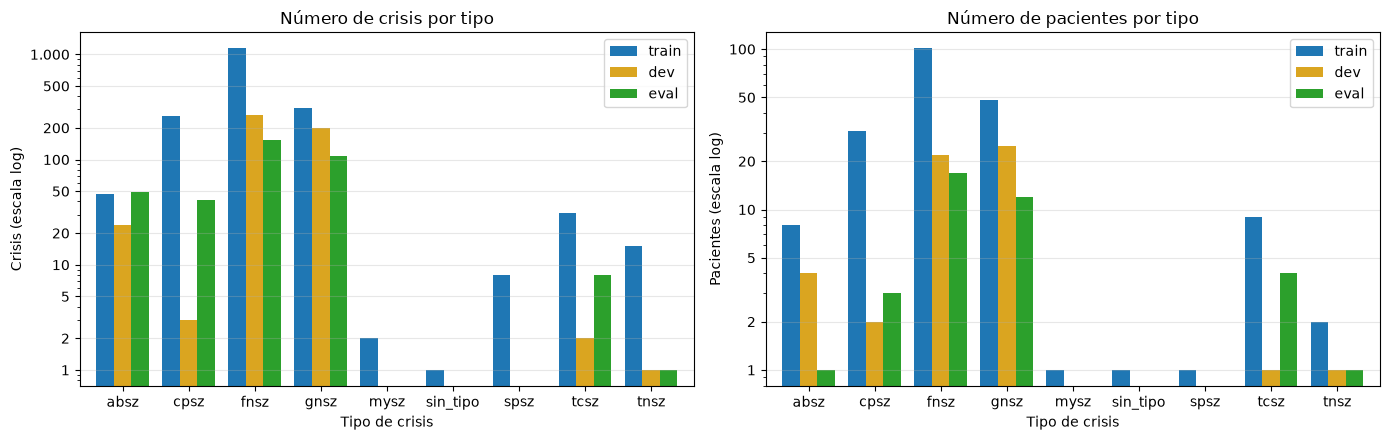

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (metrica, titulo) in zip(axes, [('crisis', 'Número de crisis por tipo'),
                                         ('pacientes', 'Número de pacientes por tipo')]):
    tabla_tipos[metrica].plot.bar(ax=ax, color=[COLORES_SPLIT[s] for s in SPLITS], width=0.8)
    ax.set_yscale('log')
    eje_log_legible(ax, 'y')
    ax.set_title(titulo)
    ax.set_xlabel('Tipo de crisis')
    ax.set_ylabel(f'{metrica.capitalize()} (escala log)')
    ax.grid(True, axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'crisis_y_pacientes_por_tipo.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Lead-in y elección del umbral para predicción

Para la **Fase 3 (predicción)** solo sirven las crisis con suficiente lead-in para que quepa una ventana preictal.

### 5.1. Elección del umbral de lead-in

No fijamos el umbral por costumbre (en la literatura se usan 30–60 min con registros de días, como CHB-MIT). Lo elegimos con los datos de TUSZ, mirando tres cosas:

1. **Cuánto dura un fichero.** Como mucho 30 min y la mediana es 10 min, así que un lead-in de 30 min es imposible dentro de un fichero.
2. **Cada cuánto llegan las crisis.** Muchas van en racimos: si la crisis anterior acaba de terminar, la "ventana preictal" sería en realidad el final de esa crisis. El umbral sirve para quedarnos con crisis precedidas de señal limpia.
3. **Cuántos pacientes quedan en eval.** Es lo que manda: con pocos pacientes en eval, cualquier métrica mide a esos pocos pacientes y no generaliza.

El umbral elegido es el último antes de que eval se quede con muy pocos pacientes.

In [6]:
# Intervalo entre crisis consecutivas del mismo fichero (excluye la primera de cada fichero)
intervalos_min = df_crisis.loc[~df_crisis.primera_del_fichero, 'leadin_s'] / 60
print('Intervalo entre crisis consecutivas (min): '
      + ', '.join(f'p{int(q * 100)}={v:.1f}' for q, v in intervalos_min.quantile([0.25, 0.5, 0.75, 0.9]).items()))
print(f'Duración de fichero: mediana {df_ficheros.edf_dur_s.median() / 60:.0f} min, máximo {df_ficheros.edf_dur_s.max() / 60:.0f} min\n')

# Crisis y pacientes que quedan con cada umbral
filas = []
for umbral in UMBRALES_LEADIN_MIN:
    fila = {'lead-in mínimo (min)': umbral}
    for s in SPLITS:
        validas = df_crisis[(df_crisis.split == s) & (df_crisis.leadin_s >= umbral * 60)]
        fila[f'{s} crisis'] = len(validas)
        fila[f'{s} pacientes'] = validas.patient.nunique()
    filas.append(fila)
tabla_umbrales = pd.DataFrame(filas).set_index('lead-in mínimo (min)')
tabla_umbrales.to_csv(RUTA_RESULTADOS / 'crisis_por_umbral_leadin.csv')
tabla_con_iconos(tabla_umbrales)

Intervalo entre crisis consecutivas (min): p25=0.2, p50=0.8, p75=2.1, p90=4.6
Duración de fichero: mediana 10 min, máximo 30 min



,🔵 train crisis,🔵 train pacientes,🟡 dev crisis,🟡 dev pacientes,🟢 eval crisis,🟢 eval pacientes
lead-in mínimo (min),,,,,,
2,534,128,278,37,169,29
5,230,89,160,30,89,26
7,97,64,98,24,33,17
10,35,30,46,17,8,6
15,8,8,19,7,4,4


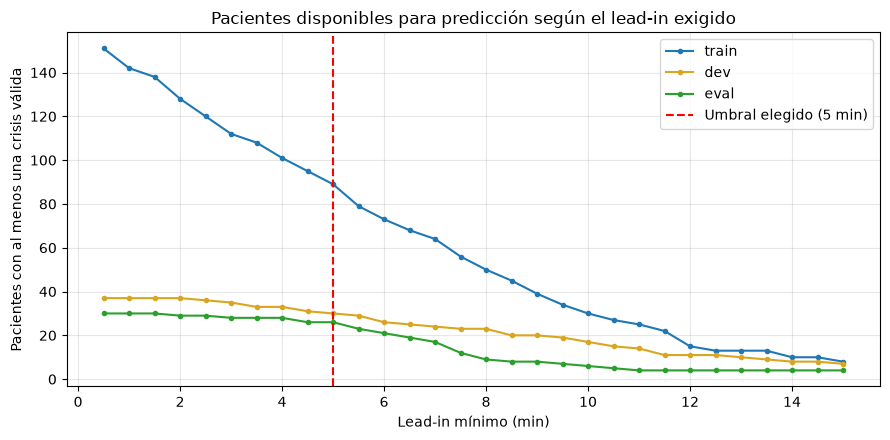

Con lead-in ≥ 5 min: 🔵 train: 230 crisis de 89 pacientes | 🟡 dev: 160 crisis de 30 pacientes | 🟢 eval: 89 crisis de 26 pacientes


In [7]:
# Curva: pacientes de cada split que conservan al menos una crisis válida según el umbral
umbrales_finos = np.arange(0.5, 15.5, 0.5)
fig, ax = plt.subplots(figsize=(9, 4.5))
for s in SPLITS:
    d = df_crisis[df_crisis.split == s]
    ax.plot(umbrales_finos, [d[d.leadin_s >= u * 60].patient.nunique() for u in umbrales_finos],
            marker='o', markersize=3, label=s, color=COLORES_SPLIT[s])
ax.axvline(LEADIN_ELEGIDO_MIN, color='red', linestyle='--', label=f'Umbral elegido ({LEADIN_ELEGIDO_MIN} min)')
ax.set_xlabel('Lead-in mínimo (min)')
ax.set_ylabel('Pacientes con al menos una crisis válida')
ax.set_title('Pacientes disponibles para predicción según el lead-in exigido')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'pacientes_segun_leadin.png', dpi=150, bbox_inches='tight')
plt.show()

elegidas = df_crisis[df_crisis.leadin_s >= LEADIN_ELEGIDO_MIN * 60]
print(f'Con lead-in ≥ {LEADIN_ELEGIDO_MIN} min: ' + ' | '.join(
    f'{con_icono(s)}: {(elegidas.split == s).sum()} crisis de {elegidas[elegidas.split == s].patient.nunique()} pacientes'
    for s in SPLITS))

### 5.2. Viabilidad para predicción por partición

Cuántas crisis (y de cuántos pacientes) superan cada umbral, y cómo se reparte el lead-in de todas las crisis.

In [8]:
# Tabla 3: viabilidad para predicción
filas = []
for s in SPLITS:
    d = df_crisis[df_crisis.split == s]
    fila = {'split': s, 'crisis': len(d)}
    for umbral in UMBRALES_LEADIN_MIN:
        validas = d[d.leadin_s >= umbral * 60]
        fila[f'lead-in ≥ {umbral} min'] = len(validas)
        fila[f'pacientes ({umbral} min)'] = validas.patient.nunique()
    filas.append(fila)
tabla_prediccion = pd.DataFrame(filas).set_index('split')
tabla_con_iconos(tabla_prediccion)

,crisis,lead-in ≥ 2 min,pacientes (2 min),lead-in ≥ 5 min,pacientes (5 min),lead-in ≥ 7 min,pacientes (7 min),lead-in ≥ 10 min,pacientes (10 min),lead-in ≥ 15 min,pacientes (15 min)
split,,,,,,,,,,,
🔵 train,1812,534,128,230,89,97,64,35,30,8,8
🟡 dev,492,278,37,160,30,98,24,46,17,19,7
🟢 eval,360,169,29,89,26,33,17,8,6,4,4


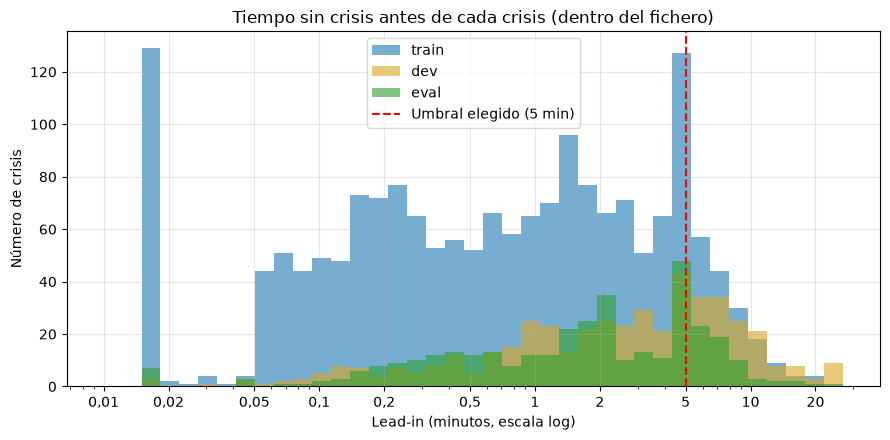

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
leadin_min = df_crisis.leadin_s / 60
bins = np.logspace(np.log10(max(leadin_min.min(), 0.01)), np.log10(leadin_min.max()), 40)
for s in SPLITS:
    ax.hist(leadin_min[df_crisis.split == s], bins=bins, alpha=0.6, label=s, color=COLORES_SPLIT[s])
ax.axvline(LEADIN_ELEGIDO_MIN, color='red', linestyle='--', label=f'Umbral elegido ({LEADIN_ELEGIDO_MIN} min)')
ax.set_xscale('log')
eje_log_legible(ax, 'x')
ax.set_xlabel('Lead-in (minutos, escala log)')
ax.set_ylabel('Número de crisis')
ax.set_title('Tiempo sin crisis antes de cada crisis (dentro del fichero)')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'distribucion_leadin.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Heterogeneidad técnica: montajes y frecuencias de muestreo

Los ficheros no se grabaron todos igual. Esta figura muestra lo que habrá que homogeneizar en la **Fase 2 (preprocesado)**: remuestrear a una frecuencia común y construir el montaje TCP de 22 canales.

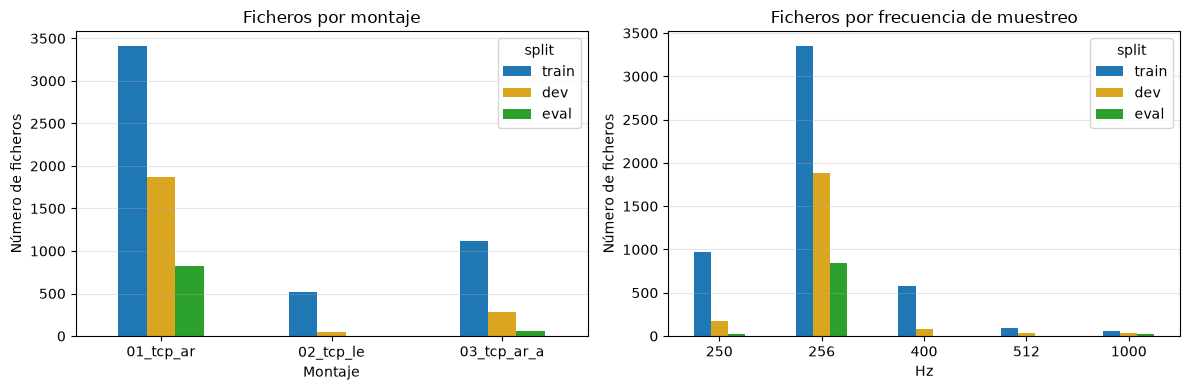

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(df_ficheros.montage, df_ficheros.split).reindex(columns=SPLITS, fill_value=0).plot.bar(
    ax=axes[0], color=[COLORES_SPLIT[s] for s in SPLITS])
axes[0].set_title('Ficheros por montaje')
axes[0].set_xlabel('Montaje')
pd.crosstab(df_ficheros.fs.round().astype(int), df_ficheros.split).reindex(columns=SPLITS, fill_value=0).plot.bar(
    ax=axes[1], color=[COLORES_SPLIT[s] for s in SPLITS])
axes[1].set_title('Ficheros por frecuencia de muestreo')
axes[1].set_xlabel('Hz')
for ax in axes:
    ax.set_ylabel('Número de ficheros')
    ax.grid(True, axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'montajes_y_frecuencias.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Resumen → `summary.txt`

Reúne en un fichero de texto las tablas de las secciones 3, 4 y 5, junto con montajes, frecuencias y duraciones. Sirve para consultar los números sin abrir el notebook.

In [11]:
duraciones = df_ficheros.edf_dur_s
texto = '\n\n'.join([
    '=== EDA TUSZ ===\n'
    f'Dataset: {config_inventario["ruta_tusz"]}\n'
    f'Inventario: {config_inventario["fecha"]} | EDA: {config["fecha"]}',
    '--- Resumen por split ---\n' + tabla_con_iconos(tabla_splits).to_string(),
    f'Pacientes compartidos entre splits (debe ser 0): {compartidos}',
    f'Montajes: {dict(Counter(df_ficheros.montage))}\n'
    f'Frecuencias de muestreo (Hz): {dict(Counter(df_ficheros.fs.round().astype(int)))}\n'
    f'Nº de señales por EDF: {dict(sorted(Counter(df_ficheros.n_signals).items()))}\n'
    f'Duración de fichero min/mediana/max (s): '
    f'{duraciones.min():.0f} / {duraciones.median():.0f} / {duraciones.max():.0f}',
    '--- Tipos de crisis (1 crisis = 1 evento del .csv_bi; tipo = etiqueta dominante del .csv) ---\n'
    + tabla_con_iconos(tabla_tipos).to_string(),
    '--- Viabilidad para predicción (lead-in = tiempo sin crisis previo dentro del mismo fichero) ---\n'
    f'Umbral elegido: {LEADIN_ELEGIDO_MIN} min\n'
    + tabla_con_iconos(tabla_prediccion).to_string(),
]) + '\n'

(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
print(texto)

=== EDA TUSZ ===
Dataset: D:\Dani\TFM IA\00.TUSZ\v2.0.6
Inventario: 2026-10-23 01:13 | EDA: 2026-10-23 01:14

--- Resumen por split ---
         pacientes  sesiones  ficheros  horas  pac. con crisis  crisis  min. en crisis
split                                                                                 
🔵 train        579      1175      5057  910.7              171    1812          1990.4
🟡 dev           53       342      2203  435.5               37     492           446.3
🟢 eval          43       126       880  128.6               30     360           398.5

Pacientes compartidos entre splits (debe ser 0): {'train/dev': 0, 'train/eval': 0, 'dev/eval': 0}

Montajes: {'02_tcp_le': 573, '03_tcp_ar_a': 1466, '01_tcp_ar': 6101}
Frecuencias de muestreo (Hz): {250: 1171, 400: 658, 256: 6071, 1000: 110, 512: 130}
Nº de señales por EDF: {17: 3, 18: 82, 20: 431, 21: 109, 25: 13, 26: 7, 27: 644, 28: 219, 29: 1040, 30: 546, 31: 571, 32: 1223, 33: 1274, 34: 1273, 35: 6, 36: 290, 41: 334, 128

## 8. Conclusiones para el TFM

Primero calculamos la **dominancia** (porcentaje) de cada montaje, frecuencia y tipo de crisis, por partición y en total (⚪ `todas`). Después, en 8.3, se resumen las conclusiones con esos números.

Las tablas se guardan en CSV para usarlas en la memoria.

### 8.1. Dominancia de montajes, frecuencias y tipos de crisis (%)

% de cada valor por partición. Si una partición tiene un reparto muy distinto a las demás, el modelo verá en test datos distintos a los de entrenamiento.

In [12]:
def porcentajes(columna, df):
    """% de cada valor de `columna` en cada partición y en el total."""
    tabla = pd.crosstab(df[columna], df.split, normalize='columns').reindex(columns=SPLITS, fill_value=0)
    tabla['todas'] = df[columna].value_counts(normalize=True)
    return (tabla * 100).round(1).sort_values('todas', ascending=False)

# Montajes y frecuencias: % de ficheros
df_ficheros['fs_hz'] = df_ficheros.fs.round().astype(int)
dominancia_montajes = porcentajes('montage', df_ficheros)
dominancia_frecuencias = porcentajes('fs_hz', df_ficheros)

# Tipos de crisis: % de crisis, pacientes, % de minutos y duración mediana
dominancia_tipos = pd.DataFrame({
    '% crisis': (df_crisis.label.value_counts(normalize=True) * 100).round(1),
    'pacientes': df_crisis.groupby('label').patient.nunique(),
    '% minutos': (df_crisis.groupby('label').dur_s.sum() / df_crisis.dur_s.sum() * 100).round(1),
    'duración mediana (s)': df_crisis.groupby('label').dur_s.median().round(0),
}).sort_values('% crisis', ascending=False)
dominancia_tipos.index.name = 'tipo'

# Tipos de crisis por partición: % de crisis de cada tipo dentro de cada partición, y nº de pacientes
tipos_por_split = pd.concat({
    '% crisis': porcentajes('label', df_crisis),
    'pacientes': df_crisis.groupby(['label', 'split']).patient.nunique().unstack()
                 .reindex(columns=SPLITS).fillna(0).astype(int)
                 .join(df_crisis.groupby('label').patient.nunique().rename('todas')),
}, axis=1)
tipos_por_split = tipos_por_split.sort_values(('% crisis', 'todas'), ascending=False)
tipos_por_split.index.name = 'tipo'

dominancia_montajes.to_csv(RUTA_RESULTADOS / 'dominancia_montajes.csv')
dominancia_frecuencias.to_csv(RUTA_RESULTADOS / 'dominancia_frecuencias.csv')
dominancia_tipos.to_csv(RUTA_RESULTADOS / 'dominancia_tipos.csv')
tipos_por_split.to_csv(RUTA_RESULTADOS / 'dominancia_tipos_por_split.csv')

print('Montajes (% de ficheros)')
display(tabla_con_iconos(dominancia_montajes))
print('Frecuencias de muestreo (% de ficheros)')
display(tabla_con_iconos(dominancia_frecuencias))
print('Montaje × frecuencia (nº de ficheros)')
display(pd.crosstab(df_ficheros.fs_hz, df_ficheros.montage))
print('Tipos de crisis (todas las particiones)')
display(tabla_con_iconos(dominancia_tipos))
print('Tipos de crisis por partición (% de crisis y nº de pacientes)')
display(tabla_con_iconos(tipos_por_split))

Montajes (% de ficheros)


split,🔵 train,🟡 dev,🟢 eval,⚪ todas
montage,,,,
01_tcp_ar,67.5,84.8,93.3,75.0
03_tcp_ar_a,22.2,12.9,6.7,18.0
02_tcp_le,10.3,2.3,0.0,7.0


Frecuencias de muestreo (% de ficheros)


split,🔵 train,🟡 dev,🟢 eval,⚪ todas
fs_hz,,,,
256,66.3,85.3,95.5,74.6
250,19.3,7.9,2.5,14.4
400,11.5,3.4,0.0,8.1
512,1.9,1.6,0.0,1.6
1000,1.0,1.8,2.0,1.4


Montaje × frecuencia (nº de ficheros)


montage,01_tcp_ar,02_tcp_le,03_tcp_ar_a
fs_hz,,,
250,597,573,1
256,5151,0,920
400,113,0,545
512,130,0,0
1000,110,0,0


Tipos de crisis (todas las particiones)


,% crisis,pacientes,% minutos,duración mediana (s)
tipo,,,,
🟥 fnsz,58.4,140,54.9,31.0
🟦 gnsz,23.2,85,24.1,35.0
🟧 cpsz,11.3,36,17.3,81.0
🟩 absz,4.5,13,0.6,7.0
🟪 tcsz,1.5,14,1.7,57.0
🟨 tnsz,0.6,4,0.3,24.0
🟫 spsz,0.3,1,0.4,84.0
🔳 mysz,0.1,1,0.8,646.0
⬛ sin_tipo,0.0,1,0.0,0.0


Tipos de crisis por partición (% de crisis y nº de pacientes)


% crisis                      pacientes                     
split       🔵 train 🟡 dev 🟢 eval ⚪ todas   🔵 train 🟡 dev 🟢 eval ⚪ todas
tipo                                                                   
🟥 fnsz         62.9  53.5   42.5    58.4       101    22     17     140
🟦 gnsz         17.2  40.4   30.0    23.2        48    25     12      85
🟧 cpsz         14.2   0.6   11.4    11.3        31     2      3      36
🟩 absz          2.6   4.9   13.6     4.5         8     4      1      13
🟪 tcsz          1.7   0.4    2.2     1.5         9     1      4      14
🟨 tnsz          0.8   0.2    0.3     0.6         2     1      1       4
🟫 spsz          0.4   0.0    0.0     0.3         1     0      0       1
🔳 mysz          0.1   0.0    0.0     0.1         1     0      0       1
⬛ sin_tipo      0.1   0.0    0.0     0.0         1     0      0       1

### 8.2. Otros datos que condicionan las siguientes fases

Desequilibrio de clases, concentración de crisis en pocos pacientes y datos que habrá que limpiar.

In [13]:
# % del tiempo de registro que es crisis (desequilibrio de clases)
pct_crisis = {s: round(df_ficheros[df_ficheros.split == s].seiz_secs_bi.sum()
                       / df_ficheros[df_ficheros.split == s].edf_dur_s.sum() * 100, 1) for s in SPLITS}
pct_crisis['todas'] = round(df_ficheros.seiz_secs_bi.sum() / df_ficheros.edf_dur_s.sum() * 100, 1)

# Concentración: cuánto aportan los pacientes con más crisis
crisis_por_paciente = df_crisis.groupby('patient').size().sort_values(ascending=False)
pct_top5 = crisis_por_paciente.head(5).sum() / crisis_por_paciente.sum() * 100
pct_top10 = crisis_por_paciente.head(10).sum() / crisis_por_paciente.sum() * 100

print(f'Tiempo en crisis (% del registro): ' + ' | '.join(f'{con_icono(k)}: {v} %' for k, v in pct_crisis.items()))
print(f'Pacientes con crisis: {df_crisis.patient.nunique()} de {df_ficheros.patient.nunique()} '
      f'({df_crisis.patient.nunique() / df_ficheros.patient.nunique() * 100:.0f} %)')
print(f'Ficheros con alguna crisis: {(df_ficheros.n_seiz_events_bi > 0).mean() * 100:.1f} %')
print(f'Crisis por paciente: mediana {crisis_por_paciente.median():.0f}, máximo {crisis_por_paciente.max()}')
print(f'Los 5 pacientes con más crisis aportan el {pct_top5:.0f} % de todas; los 10 primeros, el {pct_top10:.0f} %')
print(f'Ficheros de menos de 1 min: {(df_ficheros.edf_dur_s < 60).sum()} '
      f'({(df_ficheros.edf_dur_s < 60).mean() * 100:.0f} %)')
print(f'Crisis con duración 0 s (anotación anómala): {(df_crisis.dur_s <= 0).sum()}')
print(f'Nº de señales por EDF: de {df_ficheros.n_signals.min()} a {df_ficheros.n_signals.max()} (mediana {df_ficheros.n_signals.median():.0f})')

Tiempo en crisis (% del registro): 🔵 train: 3.6 % | 🟡 dev: 1.7 % | 🟢 eval: 5.2 % | ⚪ todas: 3.2 %
Pacientes con crisis: 238 de 675 (35 %)
Ficheros con alguna crisis: 13.5 %
Crisis por paciente: mediana 4, máximo 149
Los 5 pacientes con más crisis aportan el 20 % de todas; los 10 primeros, el 32 %
Ficheros de menos de 1 min: 653 (8 %)
Crisis con duración 0 s (anotación anómala): 1
Nº de señales por EDF: de 17 a 128 (mediana 32)


### 8.3. Conclusiones

**1. Particiones limpias**
- Ningún paciente está en dos particiones, así que no hay *data leakage* entre 🔵 `train`, 🟡 `dev` y 🟢 `eval`.
- Hay 675 pacientes, pero solo 238 (35 %) tienen crisis. Solo el 13,5 % de los ficheros contiene alguna crisis.

**2. Montajes: domina `01_tcp_ar` (75 %)**
- Reparto total: `01_tcp_ar` 75 %, `03_tcp_ar_a` 18 % y `02_tcp_le` 7 %.
- `02_tcp_le` (referencia a orejas) **solo aparece en 🔵 train** (10 %). En 🟢 eval, el 93 % de los ficheros es `01_tcp_ar`.
- Para la Fase 2 hay que construir el montaje TCP bipolar de 22 canales en todos los ficheros. Así el modelo no depende de la referencia original.
- Cada EDF trae entre 17 y 128 señales (incluye ECG, etc.). Por eso los canales se eligen por nombre de electrodo, no por posición.

**3. Frecuencias de muestreo: domina 256 Hz (75 %)**
- Reparto total: 256 Hz 75 %, 250 Hz 14 %, 400 Hz 8 %, 512 Hz 2 % y 1000 Hz 1 %.
- 🟢 eval está casi todo a 256 Hz (95 %). 🔵 train está más mezclado (66 %).
- Propuesta para la Fase 2: **remuestrear todo a 256 Hz**. Es la frecuencia mayoritaria, toca el mínimo número de ficheros y conserva de sobra las bandas útiles del EEG (< 70 Hz).

**4. Tipos de crisis: fuerte desequilibrio**
- 🟥 `fnsz` 58 % de las crisis, 🟦 `gnsz` 23 %, 🟧 `cpsz` 11 %. Entre los tres suman el 93 %.
- 🟩 `absz` es el 4,5 % de las crisis, pero solo el 0,6 % del tiempo en crisis: son muy cortas (mediana de unos 7 s).
- 🟩 `absz` en 🟢 eval: las 49 crisis son de **un único paciente**. Cualquier métrica de `absz` en eval mide a ese paciente.
- 🔳 `mysz`, 🟫 `spsz` y ⬛ `sin_tipo` tienen 1 paciente cada uno, todos en train. No se pueden evaluar.
- Propuesta para la Fase 4: clasificar `fnsz`, `gnsz`, `cpsz`, `absz` y `tcsz`, y agrupar o descartar el resto. Usar métricas que no premien la clase mayoritaria (F1 macro, matriz de confusión normalizada).

**5. Predicción (lead-in)**
- El lead-in se mide solo dentro del mismo fichero: no se puede comprobar que los tokens de una sesión sean seguidos.
- El umbral es de **5 min**: 230 crisis en train, 160 en dev y 89 en eval, de 89, 30 y 26 pacientes. Por qué no se baja: sección 5.1.1.
- Permite, por ejemplo, una ventana preictal de 4 min más 1 min de margen antes de la crisis.
- Con TUSZ no es viable la predicción clásica a 30–60 min. Lo realista es la **anticipación a corto plazo** (minutos), y conviene explicarlo así en la memoria.

**6. Otros hallazgos importantes**
- **Desequilibrio de clases**: solo un 3 % del tiempo registrado es crisis. Habrá que balancear al construir las ventanas (Fase 2) y evaluar con métricas adecuadas (sensibilidad, AUC-PR, falsas alarmas por hora), no con *accuracy*.
- **Pocos pacientes concentran muchas crisis**: los 5 primeros aportan el 20 % de todas y los 10 primeros el 32 %. Hay que limitar las ventanas por paciente para que el modelo no aprenda a "reconocer al paciente".
- **Diferencias entre particiones**: dev tiene un 1,7 % de tiempo en crisis y eval un 5,2 %. Las métricas de dev y eval no son directamente comparables.
- **Datos a limpiar**: 653 ficheros duran menos de 1 min (8 %) y hay 1 crisis con duración 0 s. Se descartan o revisan en la Fase 2.

## 9. Archivos generados

En `outputs/fase_01/02_eda/`:

- `configuracion.json`: parámetros del análisis y fecha.
- `crisis_por_umbral_leadin.csv`: crisis y pacientes por partición para cada umbral de lead-in.
- `dominancia_montajes.csv`, `dominancia_frecuencias.csv`, `dominancia_tipos.csv`, `dominancia_tipos_por_split.csv`: porcentajes de la sección 8.
- `summary.txt`: tablas resumen (con iconos).
- `figuras/`: `crisis_y_pacientes_por_tipo.png`, `pacientes_segun_leadin.png`, `distribucion_leadin.png`, `montajes_y_frecuencias.png`.